<div style="background: linear-gradient(90deg, #0b3c5d 0%, #1d6fa3 60%, #5fb3d9 100%); padding: 28px 30px; border-radius: 10px; color: white;">
  <div style="font-size: 30px; font-weight: 700; letter-spacing: 1px;">🌊 ONDAS, OLEAJE Y NIVEL DEL MAR</div>
  <div style="font-size: 19px; margin-top: 6px; opacity: 0.95;">Ejemplo didáctico · Propagación del oleaje con la ley de Snell y criterios de rotura</div>
  <div style="font-size: 13px; margin-top: 14px; opacity: 0.85;">Geomatics and Ocean Engineering Group · E.T.S. Ingenieros de Caminos, Canales y Puertos · Universidad de Cantabria</div>
</div>

<p align="left">
  <img src="../images/Image_1.png" width="100">&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;<img src="../images/Image_2.png" width="100">
</p>

### 📑 Contenido

1. [Librerías](#1.-Librerías)
2. [Datos de partida: batimetría y oleaje](#2.-Datos-de-partida:-batimetría-y-oleaje)
3. [Propagación con las funciones del curso](#3.-Propagación-con-las-funciones-del-curso)
4. [Rotura: comparación de criterios](#4.-Rotura:-comparación-de-criterios)
5. [Vista en planta: crestas, rayos y líneas de rotura](#5.-Vista-en-planta:-crestas,-rayos-y-líneas-de-rotura)
6. [Animación de la superficie libre](#6.-Animación-de-la-superficie-libre)

<div style="background-color: #e8f4fd; border-left: 6px solid #1d6fa3; padding: 10px 16px; border-radius: 6px;">
💡 Propagamos <b>un único tren de ondas monocromático</b> sobre una <b>batimetría recta y paralela</b>, con la costa orientada al norte. Usamos <b>las funciones del curso</b> de la carpeta <code>functions/</code> (<code>theta_0</code>, <code>snell_mono_prop</code>, <code>hb_calculation_vec</code>, <code>snell_mono_prop_breaking</code>), aplicadas a un solo estado de mar, para ver paso a paso cómo el oleaje <b>refracta</b>, <b>asomera</b> y <b>rompe</b>, y cómo cambia el punto de rotura según el criterio elegido.
</div>

---

## 1. Librerías

In [1]:
import os.path as op
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Funciones propias del curso (carpeta ../functions)
sys.path.append(op.abspath('..'))
from functions.snell_mono import *
from functions.Breaking import *
from functions.plots_snell import *

plt.rcParams['animation.embed_limit'] = 50  # MB

---

## 2. Datos de partida: batimetría y oleaje

- **Batimetría**: playa recta con pendiente constante $m$ y batimétricas paralelas a la costa.
  La costa está en $y = 0$ y el mar hacia el **norte** ($y > 0$): la normal a la playa apunta al norte (orientación = 0º).
- **Oleaje offshore**: altura $H_0$ y periodo $T$ en la profundidad $h_0$, procedente de la dirección $\text{Dir}_0$
  (convenio náutico: dirección **de donde viene** el oleaje, medida desde el norte en sentido horario).
- **Profundidad objetivo** $h_1$: primero se propaga hasta $h_1$ y desde ahí se calcula la rotura.

<div style="background-color: #fff8e1; border-left: 6px solid #f7c61f; padding: 10px 16px; border-radius: 6px;">
<b>✏️ INPUTS</b> — modifica estos valores en la celda siguiente
<ul style="margin-bottom: 0;">
<li><code>H0</code>: altura de ola en la profundidad offshore [m]</li>
<li><code>T</code>: periodo [s]</li>
<li><code>Dir0</code>: dirección de procedencia del oleaje [º] (300º = WNW)</li>
<li><code>h0</code>: profundidad offshore [m]</li>
<li><code>h1</code>: profundidad objetivo [m]</li>
<li><code>m</code>: pendiente de la playa [-]</li>
</ul>
</div>

In [2]:
H0 = 2.0      # altura de ola offshore [m]
T = 10.0      # periodo [s]
Dir0 = 330    # dirección de procedencia [º]

h0 = 30.0     # profundidad offshore [m]
h1 = 20.0     # profundidad objetivo [m]
m = 1/30      # pendiente de la playa [-]

orientation = 0  # costa orientada al norte (no modificar en este ejemplo)

In [3]:
# Dominio: x hacia el este, y hacia el norte (distancia a la costa)
Ly = h0 / m                    # distancia desde la costa hasta h0 [m]
Lx = 1.5 * Ly                  # ancho del dominio [m]
dx = 2.0                       # resolución [m]
x = np.arange(0, Lx + dx, dx)
y = np.arange(0, Ly + dx, dx)
X, Y = np.meshgrid(x, y)

h = np.maximum(m * y, 0.05)    # batimetría h(y); evitamos h = 0 en la orilla

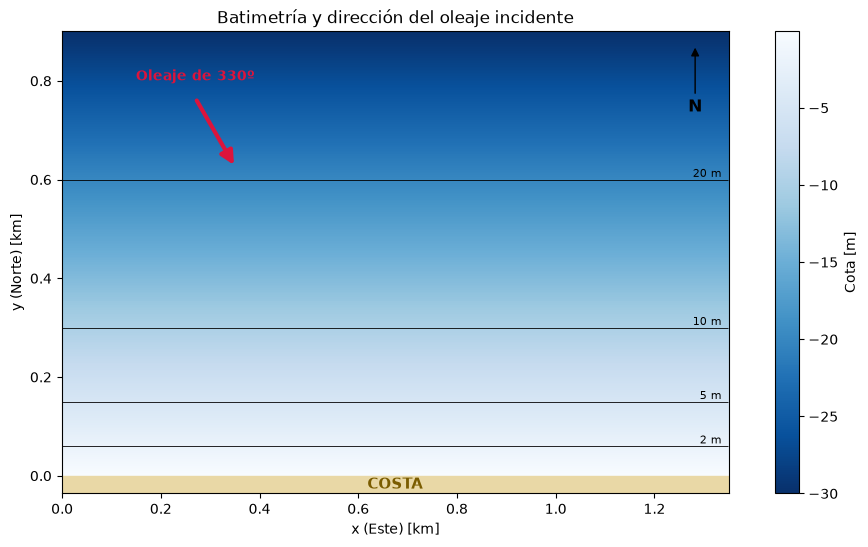

In [4]:
plot_batimetria(x, y, h,               # ejes [m] y profundidad h(y) [m]
                m,                     # pendiente (para situar las batimétricas)
                Dir0,                  # dirección de procedencia del oleaje [º]
                niveles=[2, 5, 10, 20])  # batimétricas a dibujar [m]

---

## 3. Propagación con las funciones del curso

La función `snell_propagation` (usada por `snell_mono_prop` y `snell_mono_prop_breaking`) aplica entre dos profundidades:

| Paso | Ecuación |
|---|---|
| Dispersión | $\omega^2 = gk\tanh(kh)$, $\; L = 2\pi/k$, $\; C = L/T$ |
| Ley de Snell | $\dfrac{\sin\theta}{C} = \dfrac{\sin\theta_0}{C_0}$ |
| Asomeramiento | $K_s = \sqrt{C_{g0}/C_g}$, $\; C_g = nC$, $\; n = \frac{1}{2}\left(1 + \frac{2kh}{\sinh 2kh}\right)$ |
| Refracción | $K_r = \sqrt{\cos\theta_0/\cos\theta}$ |
| Altura de ola | $H = H_0\,K_s\,K_r$ |

### <span style='color:#1d6fa3'>3.1 Propagación a lo largo de todo el perfil</span>

Creamos un DataFrame con una fila por cada punto del perfil (columnas `Hs`, `Tm`, `Dir`) y lo propagamos a todas las profundidades a la vez.

`snell_mono_prop(df, h0, h1, m, orientation)` propaga cada fila del DataFrame desde la profundidad offshore hasta la profundidad objetivo:

| Input | Descripción |
|---|---|
| `df` | DataFrame con el oleaje offshore: columnas `Hs` [m], `Tm` [s], `Dir` [º] y `theta_0` [º] (calculada antes con `theta_0`) |
| `h0` | Profundidad offshore donde se conoce el oleaje [m] |
| `h1` | Profundidad objetivo hasta la que se propaga [m]. Puede ser un número o un array (aquí, todas las profundidades del perfil `h`) |
| `m` | Pendiente de la playa [-] (solo se usa para limitar la altura con el criterio de rotura de Goda) |
| `orientation` | Orientación de la normal a la playa, desde el norte en sentido horario [º] |

Devuelve el mismo DataFrame con las columnas nuevas `H1` (altura propagada), `H1_Goda` (altura limitada por rotura),
`L0` (longitud de onda en indefinidas), `theta_1` (ángulo respecto a la normal en `h1`) y `Dir1` (dirección absoluta en `h1`).

In [5]:
# Mismo oleaje offshore repetido en cada punto del perfil (una fila por profundidad)
df_perfil = pd.DataFrame({'Hs': H0, 'Tm': T, 'Dir': float(Dir0)}, index=pd.RangeIndex(len(h)))

# Ángulo respecto a la normal a la playa (columna theta_0)
df_perfil = theta_0(df_perfil, orientation)

# Propagación con Snell desde h0 hasta cada profundidad del perfil
df_perfil = snell_mono_prop(df_perfil,    # oleaje offshore (Hs, Tm, Dir, theta_0)
                            h0,           # profundidad offshore [m]
                            h,            # profundidades de destino [m] (todo el perfil)
                            m,            # pendiente de la playa (para limitar H con Goda)
                            orientation)  # orientación de la normal a la playa [º]

print(f"Ángulo de incidencia offshore respecto a la normal: θ0 = {df_perfil['theta_0'].iloc[0]:.0f}º")
df_perfil['h'] = h
df_perfil['y'] = y
df_perfil.iloc[::50]

Ángulo de incidencia offshore respecto a la normal: θ0 = 30º


,Hs,Tm,Dir,theta_0,H1,H1_Goda,L0,theta_1,Dir1,h,y
0,2.0,10.0,330.0,30.0,6.784921,0.046460,156.130999,1.461030,358.538970,0.050000,0.0
50,2.0,10.0,330.0,30.0,2.480512,2.480512,156.130999,11.746793,348.253207,3.333333,100.0
100,2.0,10.0,330.0,30.0,2.180127,2.180127,156.130999,16.337732,343.662268,6.666667,200.0
150,2.0,10.0,330.0,30.0,2.058355,2.058355,156.130999,19.658108,340.341892,10.000000,300.0
200,2.0,10.0,330.0,30.0,2.000469,2.000469,156.130999,22.277428,337.722572,13.333333,400.0
250,2.0,10.0,330.0,30.0,1.974470,1.974470,156.130999,24.419335,335.580665,16.666667,500.0
300,2.0,10.0,330.0,30.0,1.967040,1.967040,156.130999,26.200909,333.799091,20.000000,600.0
350,2.0,10.0,330.0,30.0,1.971310,1.971310,156.130999,27.694074,332.305926,23.333333,700.0
400,2.0,10.0,330.0,30.0,1.983195,1.983195,156.130999,28.948167,331.051833,26.666667,800.0
450,2.0,10.0,330.0,30.0,2.000000,2.000000,156.130999,30.000000,330.000000,30.000000,900.0


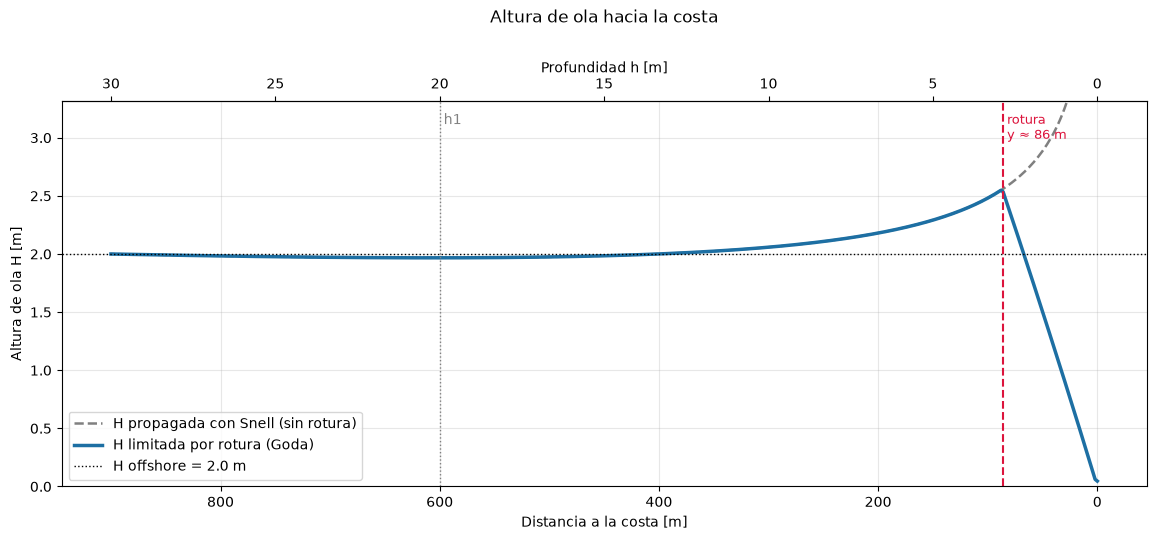

In [6]:
plot_altura_perfil(df_perfil['y'].values,        # distancia a la costa [m]
                   m,                             # pendiente (eje superior de profundidades)
                   df_perfil['H1'].values,        # H propagada con Snell, sin rotura [m]
                   df_perfil['H1_Goda'].values,   # H limitada por el criterio de Goda [m]
                   H0,                            # altura offshore [m]
                   y_h1=h1 / m)                   # posición de la profundidad objetivo h1 [m]

In [7]:
# Variables auxiliares para las gráficas (mismas funciones que usa snell_mono_prop)
H_snell = df_perfil['H1'].values                    # H propagada con Snell, sin rotura
theta_1 = df_perfil['theta_1'].values               # |θ| respecto a la normal
L_0, k_0, C_0 = waves_dispersion(T, h0)
L, k, C = waves_dispersion(T, h)
Ks_perfil = Ks(cg(L_0, T, h0), cg(L, T, h))
Kr_perfil = Kr(df_perfil['theta_0'].values, theta_1)

### <span style='color:#1d6fa3'>3.2 Evolución de las variables hacia la costa</span>

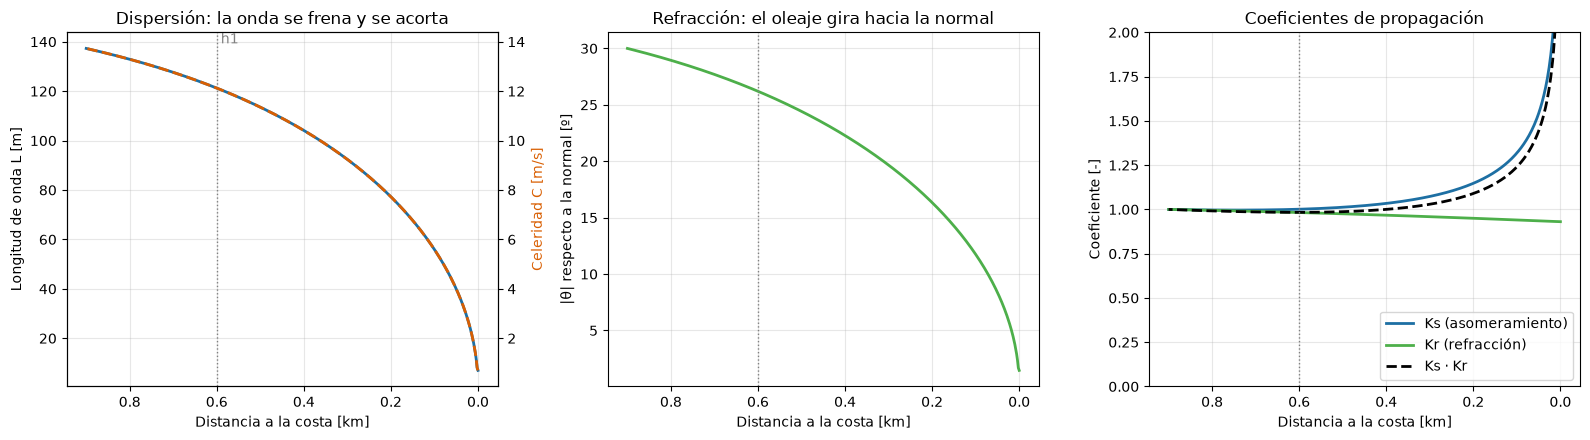

In [8]:
plot_perfil_propagacion(y,                  # distancia a la costa [m]
                        L, C,               # longitud de onda [m] y celeridad [m/s]
                        theta_1,            # |θ| respecto a la normal [º]
                        Ks_perfil, Kr_perfil,  # coeficientes de asomeramiento y refracción
                        y_h1=h1 / m)        # posición de la profundidad objetivo h1 [m]

---

## 4. Rotura: comparación de criterios

Un criterio de rotura da la **altura de ola máxima $H_b$ que puede existir en una profundidad $h$**. La función
`hb_calculation_vec` busca la **profundidad de rotura $h_b$**: el punto en el que la altura propagada con Snell
desde $h_1$ alcanza ese límite, $H(h_b) = H_b(h_b)$. Después `snell_mono_prop_breaking` propaga desde $h_1$ hasta $h_b$.

| Criterio | Expresión | Depende de | Características y cuándo usarlo |
|---|---|---|---|
| **McCowan** (1894) | $H_b = 0.78\,h$ | $h$ | Teórico (onda solitaria en fondo horizontal). Índice de rotura fijo $\gamma_b = 0.78$. Es el más sencillo: útil para estimaciones rápidas en aguas someras. No tiene en cuenta ni la pendiente ni el periodo. |
| **Miche** (1944) | $H_b = 0.142\,L\tanh(kh)$ | $h$, $T$ | Teórico: peralte máximo de una onda ($H/L \approx 1/7$ en indefinidas). Válido en cualquier profundidad (en someras tiende a $H_b \approx 0.89\,h$). No tiene en cuenta la pendiente. |
| **Goda** (1970) | $H_b = 0.17\,L_0\left[1-\exp\left(-1.5\pi\dfrac{h}{L_0}(1+15m^{4/3})\right)\right]$ | $h$, $T$, $m$ | Empírico (ensayos de laboratorio). Incluye la pendiente: en playas más pendientes la ola rompe más alta y más cerca de la costa. Es el más usado en ingeniería de costas. |
| **Weggel** (1972) | $\dfrac{H_b}{h_b} = b - a\dfrac{H_b}{gT^2}$, $\; a = 43.8(1-e^{-19m})$, $\; b = \dfrac{1.56}{1+e^{-19.5m}}$ | $h$, $T$, $m$ | Empírico (laboratorio), calibrado para pendientes $m \lesssim 0.1$. Incluye pendiente y periodo; suele dar los $\gamma_b$ más altos en playas pendientes. |
| **Kaminsky–Kraus** (1993) | $\dfrac{H_b}{h_b} = \gamma_b = 1.2\,I_r^{0.27}$, $\; I_r = \dfrac{m}{\sqrt{H_0/L_0}}$ | $h$, $m$, $H_0/L_0$ | Empírico (datos de campo y laboratorio). $\gamma_b$ depende del número de Iribarren: crece con la pendiente y con oleajes poco peraltados (mar de fondo). Necesita el oleaje en indefinidas. |

Todas las funciones están en `functions/Breaking.py` (`Hb_McCowan`, `Hb_Miche`, `Hb_Goda`, `Hb_Weggel`, `gamma_KaminskyKraus`, `hb_calculation_vec`).

El criterio de **Kaminsky–Kraus** da un índice de rotura $\gamma_b = H_b/h_b$ constante para cada estado de mar, que
depende de la pendiente y del peralte del oleaje **en indefinidas** a través del número de Iribarren. Como nuestro dato
$H_0$ está en $h_0$, primero lo propagamos a indefinidas (`h = np.inf`) y después lo definimos como una función más,
$H_b(T, h, m) = \gamma_b\,h$, junto al resto de criterios (todos con funciones de `functions/Breaking.py`).

In [9]:
# Oleaje en indefinidas (necesario para el número de Iribarren)
H0_ind, theta0_ind = snell_propagation(H0, T, min_dist(orientation, Dir0), h0, np.inf)
L0 = g * T**2 / (2 * np.pi)
gamma_kk = gamma_KaminskyKraus(m, H0_ind, T)
print(f'Oleaje en indefinidas: H0 = {H0_ind:.2f} m,  θ0 = {theta0_ind:.1f}º')
print(f'Ir = m / √(H0/L0) = {Iro(m, H0_ind, L0):.3f}   ->   γb = 1.2 · Ir^0.27 = {gamma_kk:.3f}')

# Criterios de rotura que vamos a comparar: cada uno es una función Hb(T, h, m)
criterios = {
    'McCowan':        lambda T, h, m: Hb_McCowan(h),     # Hb = 0.78 h
    'Miche':          lambda T, h, m: Hb_Miche(T, h),    # Hb = 0.142 L tanh(kh)
    'Goda':           Hb_Goda,                           # depende de h, L0 y m
    'Weggel':         Hb_Weggel,                         # depende de h, T y m
    'Kaminsky-Kraus': lambda T, h, m: gamma_kk * h,      # Hb = γb h, con γb a partir del número de Iribarren
}
list(criterios)

Oleaje en indefinidas: H0 = 2.24 m,  θ0 = 34.7º
Ir = m / √(H0/L0) = 0.278   ->   γb = 1.2 · Ir^0.27 = 0.850


['McCowan', 'Miche', 'Goda', 'Weggel', 'Kaminsky-Kraus']

<div style="background-color: #e8f4fd; border-left: 6px solid #1d6fa3; padding: 10px 16px; border-radius: 6px;">
💡 Si el oleaje llega muy oblicuo a $h_0$, al propagarlo hacia indefinidas se vuelve casi rasante ($\theta_0 \to 90º$) y
$K_r = \sqrt{\cos\theta_0/\cos\theta}$ hace que $H_0$ crezca mucho (con $\text{Dir}_0 = 300º$: $\theta_0 \approx 80º$ y $H_0 \approx 3.7$ m).
Por suerte $\gamma_b \propto H_0^{-0.135}$ es poco sensible a $H_0$, pero conviene tenerlo en cuenta al usar criterios
que dependen del oleaje en indefinidas.
</div>

### <span style='color:#1d6fa3'>4.1 Propagación hasta la rotura con cada criterio</span>

Para cada criterio propagamos a $h_1$, calculamos $h_b$ y propagamos hasta ella.

In [10]:
# Oleaje en la profundidad objetivo h1
df_1 = pd.DataFrame({'Hs': [H0], 'Tm': [T], 'Dir': [float(Dir0)]})
df_1 = theta_0(df_1, orientation)
df_1 = snell_mono_prop(df_1, h0, h1, m, orientation)

# Rotura con cada criterio
rotura = []
for criterio in criterios:
    df_c = df_1.copy()
    df_c['hb'] = hb_calculation_vec(df_c['H1_Goda'], df_c['Tm'], df_c['theta_1'], h1, m, criterio=criterios[criterio])
    df_c = snell_mono_prop_breaking(df_c, h1, m, orientation)
    df_c['Criterio'] = criterio
    rotura.append(df_c)

tabla_rotura = pd.concat(rotura).set_index('Criterio')
tabla_rotura['Distancia a costa [m]'] = tabla_rotura['hb'] / m
tabla_rotura['Hb/hb'] = tabla_rotura['Hb'] / tabla_rotura['hb']
tabla_rotura[['H1_Goda', 'theta_1', 'hb', 'Distancia a costa [m]', 'Hb', 'Hb/hb', 'thetab', 'Dirb']].round(2)

,H1_Goda,theta_1,hb,Distancia a costa [m],Hb,Hb/hb,thetab,Dirb
Criterio,,,,,,,,
McCowan,1.97,26.2,3.21,96.18,2.50,0.78,11.53,348.47
Miche,1.97,26.2,2.97,88.97,2.54,0.86,11.10,348.90
Goda,1.97,26.2,2.89,86.68,2.56,0.88,10.96,349.04
Weggel,1.97,26.2,2.68,80.30,2.60,0.97,10.56,349.44
Kaminsky-Kraus,1.97,26.2,2.99,89.61,2.54,0.85,11.14,348.86


### <span style='color:#1d6fa3'>4.2 ¿Dónde rompe el oleaje?</span>

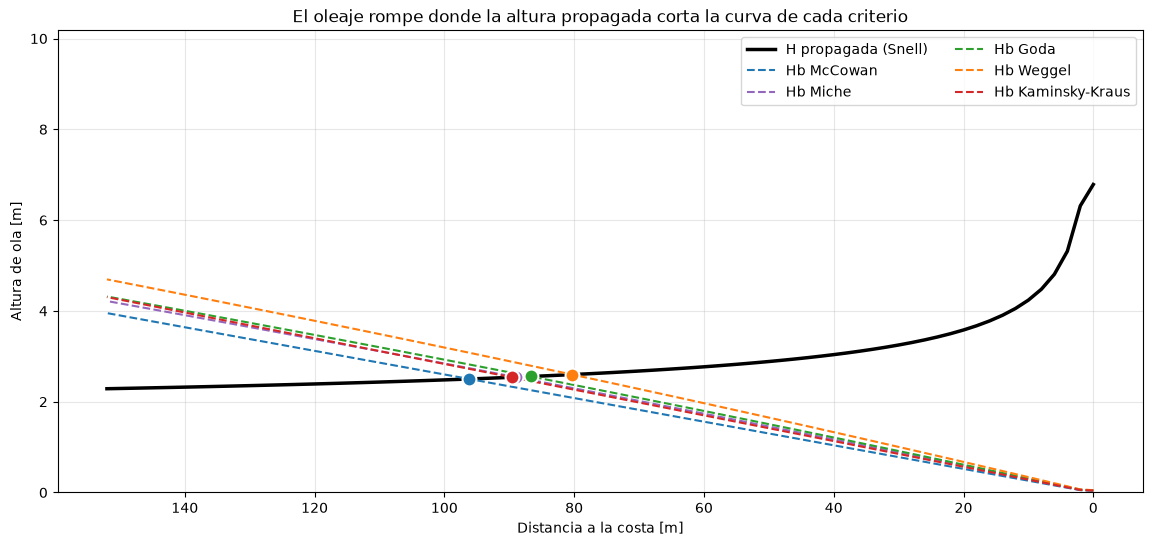

In [11]:
plot_rotura_criterios(y, h,          # distancia a la costa [m] y profundidad [m]
                      H_snell,       # altura propagada con Snell, sin rotura [m]
                      tabla_rotura,  # resultados de rotura de cada criterio
                      criterios,     # diccionario {nombre: Hb(T, h, m)}
                      T, m)          # periodo [s] y pendiente

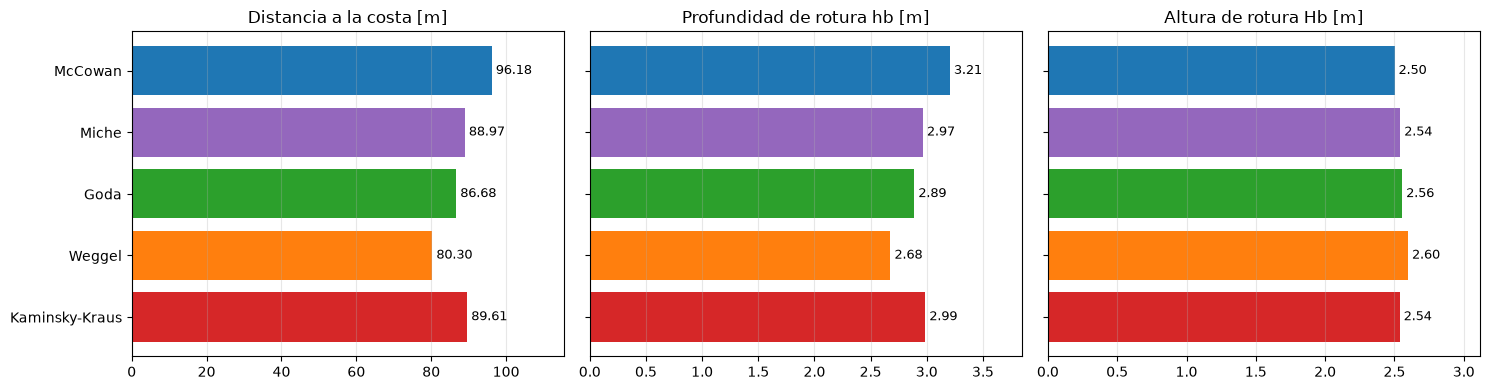

In [12]:
plot_barras_rotura(tabla_rotura)

<div style="background-color: #e8f4fd; border-left: 6px solid #1d6fa3; padding: 10px 16px; border-radius: 6px;">
🔎 <b>McCowan</b> solo depende de la profundidad, mientras que <b>Goda</b>, <b>Weggel</b> y <b>Kaminsky–Kraus</b> tienen en cuenta la pendiente y el periodo (Kaminsky–Kraus a través del número de Iribarren, que incluye el peralte del oleaje en indefinidas): en playas más pendientes el oleaje puede alcanzar alturas mayores antes de romper. Prueba a cambiar <code>m</code> o <code>T</code> y observa cómo se separan los criterios.
</div>

---

## 5. Vista en planta: crestas, rayos y líneas de rotura

Con batimétricas paralelas, la componente del número de onda a lo largo de la costa es constante (esto es
precisamente la ley de Snell): $k_x = k\sin\theta = \text{cte}$. La fase de la onda es

$$ S(x,y) = k_x\,x + \int_y^{y_0} k\cos\theta\, dy' $$

- Las **crestas** son las líneas $S = 2\pi n$.
- Los **rayos** (trayectorias de la energía) son perpendiculares a las crestas: $\dfrac{dx}{dy} = -\tan\theta$.

El ángulo con signo lo obtenemos de la dirección local `Dir1` que devuelve `snell_mono_prop`.

In [13]:
# Ángulo local con signo respecto a la normal (positivo = oleaje viene del este de la normal)
theta_s = (df_perfil['Dir1'].values - orientation + 180) % 360 - 180

# Fase S(x, y)
kx = -k * np.sin(np.radians(theta_s))     # constante (Snell)
ky = k * np.cos(np.radians(theta_s))
int_ky = np.concatenate([[0], np.cumsum(0.5 * (ky[1:] + ky[:-1]) * np.diff(y))])
S = kx[-1] * X + (int_ky[-1] - int_ky)[:, None]

# Rayos: x(y) partiendo de varios puntos del borde offshore
tan_t = -np.tan(np.radians(theta_s))
int_tan = np.concatenate([[0], np.cumsum(0.5 * (tan_t[1:] + tan_t[:-1]) * np.diff(y))])
desplaz = int_tan[-1] - int_tan
x_inicio = np.arange(-Lx, Lx, Lx / 12)

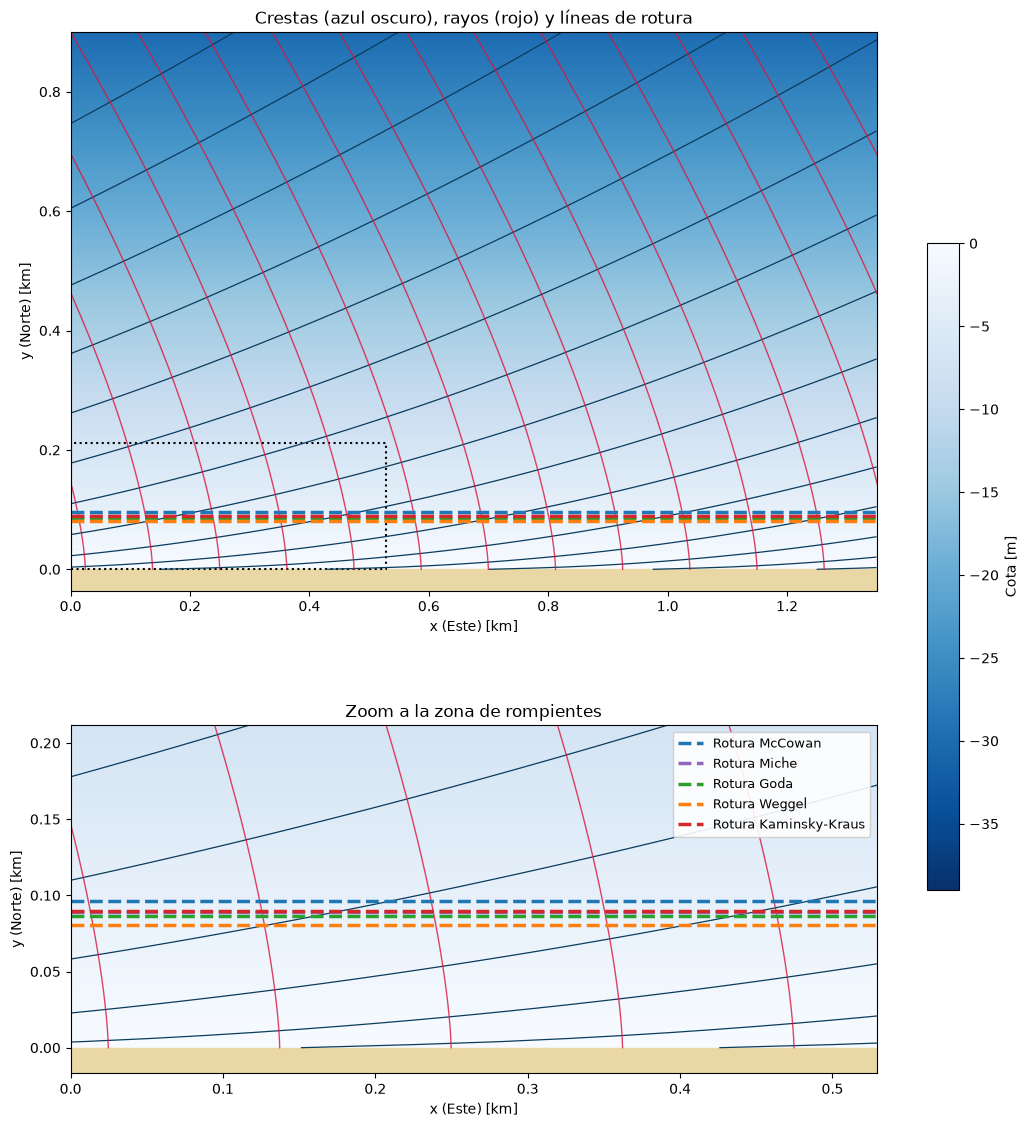

In [14]:
plot_planta(x, y, h,          # ejes [m] y profundidad h(y) [m]
            S,                # fase de la onda S(x, y): las crestas son S = 2πn
            x_inicio, desplaz,  # punto de partida de cada rayo y su desplazamiento lateral [m]
            tabla_rotura)     # posición de la rotura de cada criterio

<div style="background-color: #e8f4fd; border-left: 6px solid #1d6fa3; padding: 10px 16px; border-radius: 6px;">
💡 Al acercarse a la costa las <b>crestas se juntan</b> (L disminuye) y se van <b>poniendo paralelas a la costa</b>, mientras los <b>rayos se separan</b>: la energía se reparte en un frente más ancho y por eso $K_r < 1$.
</div>

---

## 6. Animación de la superficie libre

Representamos $\eta(x,y,t) = \dfrac{H(y)}{2}\cos\left(S(x,y) - \omega t\right)$ a lo largo de un periodo.
Fuera de la zona de rompientes $H$ es la altura propagada con Snell; dentro, $H$ queda limitada por el criterio
de rotura elegido.

<div style="background-color: #fff8e1; border-left: 6px solid #f7c61f; padding: 10px 16px; border-radius: 6px;">
<b>✏️ INPUTS</b> — modifica estos valores en la celda siguiente
<ul style="margin-bottom: 0;">
<li><code>criterio_anim</code>: criterio de rotura para la animación: 'McCowan', 'Miche', 'Goda', 'Weggel' o 'Kaminsky-Kraus'</li>
</ul>
</div>

In [15]:
criterio_anim = 'Goda'

In [16]:
y_b = tabla_rotura.loc[criterio_anim, 'Distancia a costa [m]']        # posición de la rotura [m]
H_anim = np.where(y <= y_b, criterios[criterio_anim](T, h, m), H_snell)  # dentro de rompientes, H limitada por el criterio

animacion_superficie(x, y,            # ejes [m]
                     S,               # fase de la onda S(x, y)
                     H_anim,          # altura de ola en cada punto del perfil [m]
                     T,               # periodo [s]
                     y_b, criterio_anim,  # rotura (para la etiqueta)
                     n_frames=24, paso=3,  # fotogramas y submuestreo espacial
                     zoom=True)            # añade un panel ampliado en la zona de rompientes

<div style="background-color: #e8f4fd; border-left: 6px solid #1d6fa3; padding: 10px 16px; border-radius: 6px;">
🧪 Prueba a cambiar <code>Dir0</code> (por ejemplo 330º o 30º), el periodo <code>T</code> o la pendiente <code>m</code> en la celda de INPUTS y vuelve a ejecutar el notebook para ver cómo cambian la refracción, el asomeramiento y el punto de rotura con cada criterio.
</div>